In [9]:
from dotenv import load_dotenv
load_dotenv()

import sys
sys.path.append("../streamlit_app")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from utils import load_data

# Plots plus grands par défaut
plt.rcParams["figure.figsize"] = (10, 5)

# Chargement des deux tables (via Postgres, pas via CSV)
df_km = load_data("data/activities_km.csv")
df_act = load_data("data/activities_clean.csv")

print(f"df_km  : {len(df_km):>4} lignes ({df_km['activity_id'].nunique()} sorties)")
print(f"df_act : {len(df_act):>4} sorties")
print(f"\nColonnes df_km : {list(df_km.columns)}")
df_km.head(-1)

df_km  :  765 lignes (127 sorties)
df_act :  127 sorties

Colonnes df_km : ['activity_id', 'km_index', 'km_distance_m', 'pace_min_per_km', 'elev_gain_m', 'elev_loss_m', 'elev_delta_m', 'avg_grade_pct', 'avg_heartrate', 'avg_cadence', 'distance_before_km', 'is_partial', 'fraction_completed', 'elev_gain_before_m']


,activity_id,km_index,km_distance_m,pace_min_per_km,elev_gain_m,elev_loss_m,elev_delta_m,avg_grade_pct,avg_heartrate,avg_cadence,distance_before_km,is_partial,fraction_completed,elev_gain_before_m
0,11346532154,1,997.5,4.611529,9.6,1.1,8.5,0.852130,NaN,NaN,0.0,False,0.333333,0.0
1,11346532154,2,997.7,4.360028,0.6,3.3,-2.7,-0.270622,NaN,NaN,1000.0,False,0.666667,9.6
2,11346532154,3,568.7,4.161538,2.2,8.0,-5.8,-1.019870,NaN,NaN,2000.0,True,1.000000,10.2
3,11351598892,1,997.5,4.461153,3.0,11.6,-8.6,-0.862155,NaN,NaN,0.0,False,0.250000,0.0
4,11351598892,2,996.1,4.467423,4.7,1.8,2.9,0.291135,NaN,NaN,1000.0,False,0.500000,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
759,19947595873,2,923.8,6.982031,7.4,11.2,-3.8,-0.411344,141.147287,77.770026,1000.0,True,1.000000,7.8
760,19959662058,1,997.5,6.549708,8.1,5.0,3.1,0.310777,126.162850,75.605598,0.0,False,0.333333,0.0
761,19959662058,2,998.1,6.178406,7.0,11.4,-4.4,-0.440838,141.986523,77.407008,1000.0,False,0.666667,8.1
762,19959662058,3,469.9,5.852309,2.8,1.5,1.3,0.276655,141.777108,77.668675,2000.0,True,1.000000,15.1


Distribution des allures au km

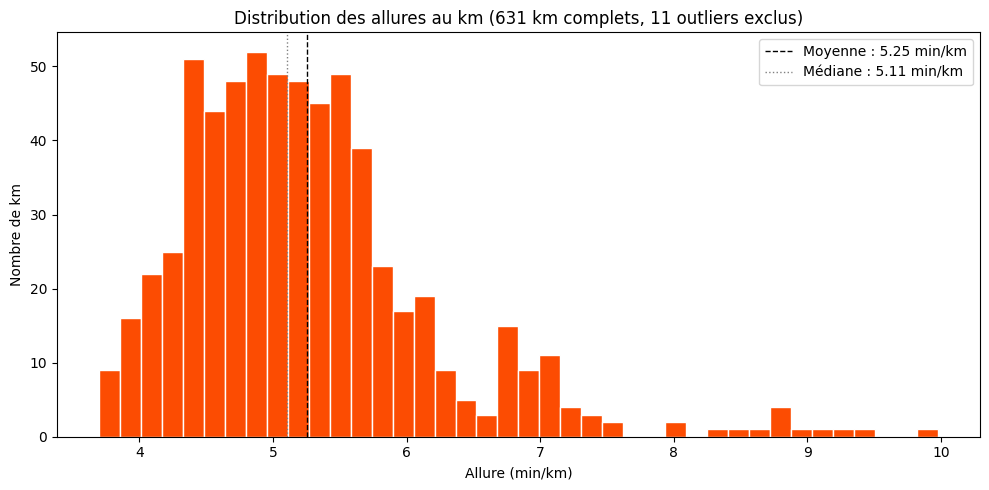

count    631.00
mean       5.25
std        0.95
min        3.70
25%        4.61
50%        5.11
75%        5.62
max        9.98
Name: pace_min_per_km, dtype: float64


In [ ]:
# Filtres : km complets et allure entre 3 et 10 min/km
mask = (~df_km["is_partial"]) & (df_km["pace_min_per_km"].between(3, 10))
paces = df_km.loc[mask, "pace_min_per_km"]
n_filtered = (~df_km["is_partial"]).sum() - len(paces)

fig, ax = plt.subplots()
ax.hist(paces, bins=40, edgecolor="white", color="#FC4C02")
ax.axvline(paces.mean(), color="black", linestyle="--", linewidth=1, label=f"Moyenne : {paces.mean():.2f} min/km")
ax.axvline(paces.median(), color="grey", linestyle=":", linewidth=1, label=f"Médiane : {paces.median():.2f} min/km")

ax.set_xlabel("Allure (min/km)")
ax.set_ylabel("Nombre de km")
ax.set_title(f"Distribution des allures au km ({len(paces)} km complets, {n_filtered} outliers exclus)")
ax.legend()
plt.tight_layout()
plt.show()

print(paces.describe().round(2))

In [11]:
# Change cette valeur : mets l'ID d'une activité que tu connais
# On prend la plus récente par défaut
activity_id = 12515904766
# activity_id = df_km["activity_id"].max()

# Ou choisis manuellement, exemple : activity_id = 12345678901

zoom = df_km[df_km["activity_id"] == activity_id].sort_values("km_index")
print(f"Activité {activity_id} — {len(zoom)} km ({zoom['is_partial'].sum()} partiel)")
print()
print(zoom[["km_index", "km_distance_m", "pace_min_per_km", 
            "elev_gain_m", "elev_delta_m", "avg_grade_pct",
            "avg_heartrate", "avg_cadence", "is_partial"]].to_string(index=False))

# Le total pour vérifier
total_dist = zoom["km_distance_m"].sum() / 1000
total_gain = zoom["elev_gain_m"].sum()
print(f"\nTotal calculé : {total_dist:.2f} km, D+ {total_gain:.0f} m")
print(f"URL Strava    : https://www.strava.com/activities/{activity_id}")

Activité 12515904766 — 11 km (1 partiel)

 km_index  km_distance_m  pace_min_per_km  elev_gain_m  elev_delta_m  avg_grade_pct  avg_heartrate  avg_cadence  is_partial
        1          999.2         4.536963          1.7          -5.9      -0.590472            NaN          NaN       False
        2          996.9         4.413682          2.4          -4.6      -0.461430            NaN          NaN       False
        3          996.6         4.515352          4.4           0.8       0.080273            NaN          NaN       False
        4          995.8         4.535717         12.9          11.8       1.184977            NaN          NaN       False
        5          995.8         4.569191          6.5           6.2       0.622615            NaN          NaN       False
        6          994.2         4.643600          5.3           4.3       0.432509            NaN          NaN       False
        7          996.8         4.430845          0.2         -14.7      -1.474719       

C:\Users\nordi\AppData\Local\Temp\ipykernel_14176\2719488653.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_by_bin, labels=["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"], patch_artist=True, showfliers=False)


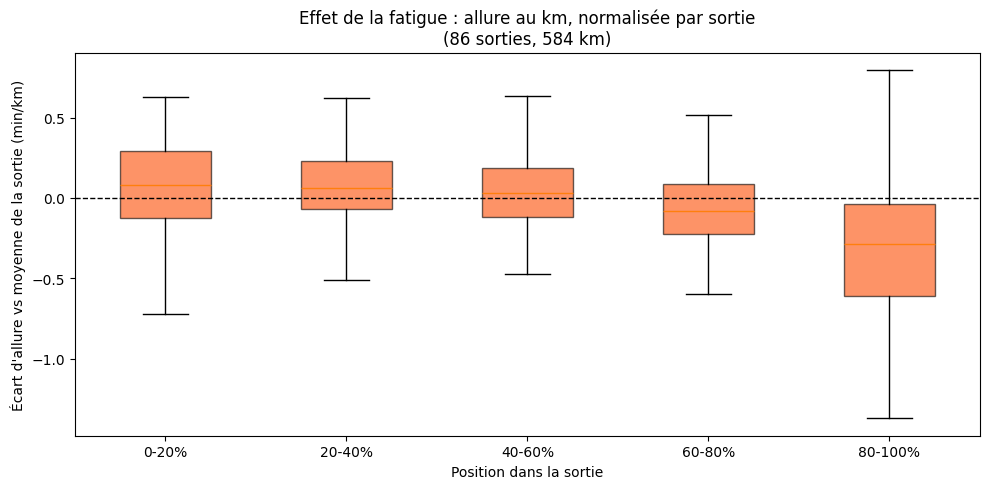


Écart moyen d'allure par tranche (min/km, négatif = plus rapide) :
               mean  median  count
fraction_bin                      
0-20%         0.136   0.079    103
20-40%        0.088   0.064    124
40-60%        0.048   0.028    136
60-80%       -0.023  -0.079    125
80-100%      -0.296  -0.284     96


In [13]:
# Filtres : km complets, allures crédibles, au moins 3 km dans la sortie
mask = (~df_km["is_partial"]) & (df_km["pace_min_per_km"].between(3, 10))
sub = df_km[mask].copy()

# Compter le nombre de km complets par sortie, garder seulement les sorties ≥ 3 km
counts = sub.groupby("activity_id")["km_index"].transform("count")
sub = sub[counts >= 3]

# Normaliser : allure - allure moyenne de la sortie
sub["pace_centered"] = sub.groupby("activity_id")["pace_min_per_km"].transform(lambda x: x - x.mean())

# On veut un boxplot par tranche de fraction complétée
sub["fraction_bin"] = pd.cut(sub["fraction_completed"], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"])

fig, ax = plt.subplots()
data_by_bin = [sub[sub["fraction_bin"] == b]["pace_centered"].values for b in ["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"]]
bp = ax.boxplot(data_by_bin, labels=["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"], patch_artist=True, showfliers=False)

# Coloration en orange
for patch in bp["boxes"]:
    patch.set_facecolor("#FC4C02")
    patch.set_alpha(0.6)

ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Position dans la sortie")
ax.set_ylabel("Écart d'allure vs moyenne de la sortie (min/km)")
ax.set_title(f"Effet de la fatigue : allure au km, normalisée par sortie\n({sub['activity_id'].nunique()} sorties, {len(sub)} km)")
plt.tight_layout()
plt.show()

# Chiffres pour illustrer
print("\nÉcart moyen d'allure par tranche (min/km, négatif = plus rapide) :")
print(sub.groupby("fraction_bin", observed=True)["pace_centered"].agg(["mean", "median", "count"]).round(3))

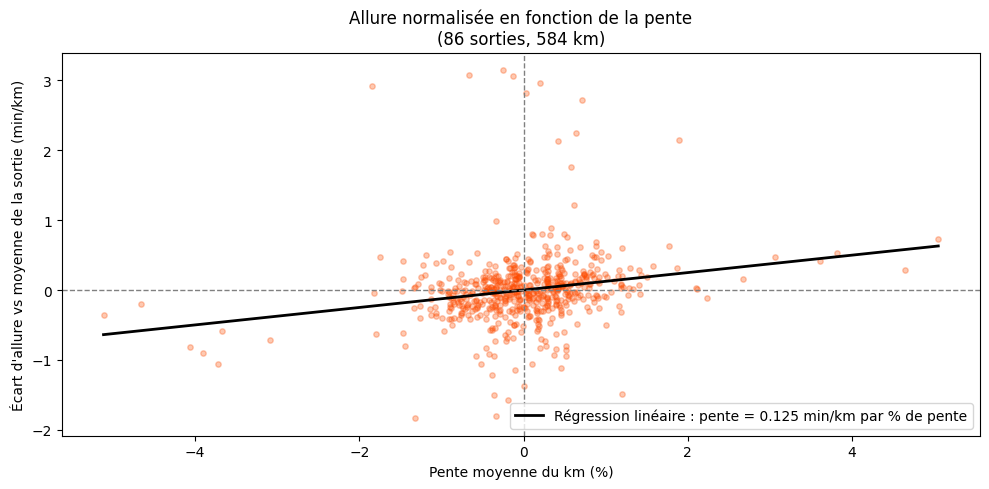


Coefficient de corrélation Pearson : 0.209
Interprétation : chaque +1% de pente = allure ralentie de 7.5 s/km en moyenne


In [ ]:
# Filtres : km complets, allures crédibles
mask = (~df_km["is_partial"]) & (df_km["pace_min_per_km"].between(3, 10))
sub = df_km[mask].copy()

# On garde uniquement les sorties avec >=3 km complets
counts = sub.groupby("activity_id")["km_index"].transform("count")
sub = sub[counts >= 3]

# Normalisation intra-sortie : allure - allure moyenne de la sortie
sub["pace_centered"] = sub.groupby("activity_id")["pace_min_per_km"].transform(lambda x: x - x.mean())

# On borne la pente pour rester dans le domaine crédible (au-delà de 10%, ce sont des anomalies GPS)
sub = sub[sub["avg_grade_pct"].between(-10, 10)]

fig, ax = plt.subplots()
ax.scatter(sub["avg_grade_pct"], sub["pace_centered"],
           alpha=0.3, s=15, color="#FC4C02")

# Régression linéaire simple pour visualiser la tendance
import numpy as np
x = sub["avg_grade_pct"].values
y = sub["pace_centered"].values
coeffs = np.polyfit(x, y, deg=1)
xline = np.linspace(x.min(), x.max(), 100)
yline = np.polyval(coeffs, xline)
ax.plot(xline, yline, color="black", linewidth=2,
        label=f"Régression linéaire : pente = {coeffs[0]:.3f} min/km par % de pente")

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Pente moyenne du km (%)")
ax.set_ylabel("Écart d'allure vs moyenne de la sortie (min/km)")
ax.set_title(f"Allure normalisée en fonction de la pente\n({sub['activity_id'].nunique()} sorties, {len(sub)} km)")
ax.legend()
plt.tight_layout()
plt.show()

# Coefficient de corrélation pour quantifier
corr = sub[["avg_grade_pct", "pace_centered"]].corr().iloc[0, 1]
print(f"\nCoefficient de corrélation Pearson : {corr:.3f}")
print(f"Interprétation : chaque +1% de pente = allure ralentie de {coeffs[0]*60:.1f} s/km en moyenne")

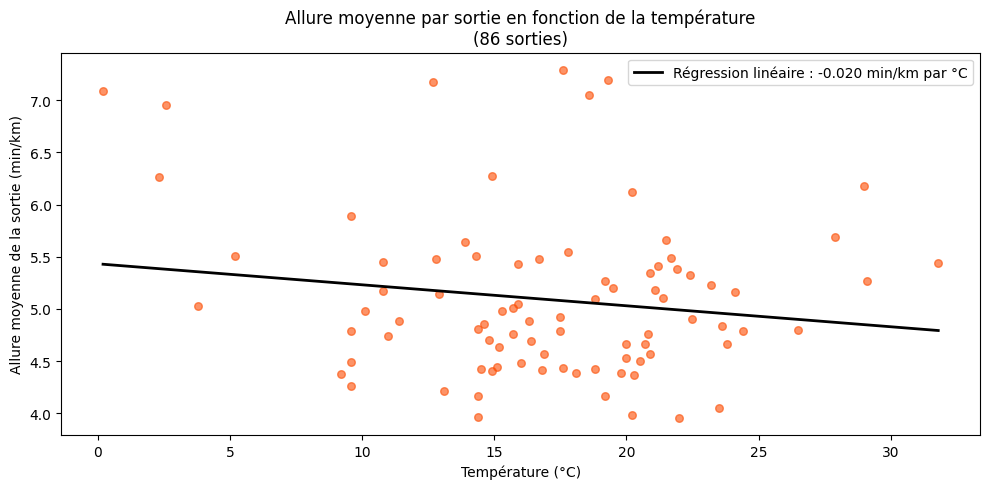


Coefficient de corrélation Pearson : -0.155
Interprétation : chaque +1°C = allure ralentie de -1.2 s/km en moyenne


In [16]:
# JOIN pour récupérer la température de chaque sortie
df_merged = df_km.merge(
    df_act[["id", "weather_temperature"]],
    left_on="activity_id", right_on="id", how="left"
)

# Filtres habituels + température présente
mask = (
    (~df_merged["is_partial"])
    & (df_merged["pace_min_per_km"].between(3, 10))
    & (df_merged["weather_temperature"].notna())
)
sub = df_merged[mask].copy()

# Normalisation intra-sortie
counts = sub.groupby("activity_id")["km_index"].transform("count")
sub = sub[counts >= 3]
sub["pace_centered"] = sub.groupby("activity_id")["pace_min_per_km"].transform(lambda x: x - x.mean())

# Note importante : puisque la température est constante dans une sortie,
# la normalisation intra-sortie va TOUT écraser vers 0 pour cette variable.
# On travaille donc sur l'allure BRUTE ici, pas normalisée, en agrégeant par sortie.
sortie_agg = df_merged[mask].groupby("activity_id").agg(
    pace_moyenne=("pace_min_per_km", "mean"),
    temp=("weather_temperature", "first"),
    n_km=("km_index", "count"),
).reset_index()
sortie_agg = sortie_agg[sortie_agg["n_km"] >= 3]

fig, ax = plt.subplots()
ax.scatter(sortie_agg["temp"], sortie_agg["pace_moyenne"],
           alpha=0.6, s=30, color="#FC4C02")

# Régression linéaire
import numpy as np
x = sortie_agg["temp"].values
y = sortie_agg["pace_moyenne"].values
coeffs = np.polyfit(x, y, deg=1)
xline = np.linspace(x.min(), x.max(), 100)
yline = np.polyval(coeffs, xline)
ax.plot(xline, yline, color="black", linewidth=2,
        label=f"Régression linéaire : {coeffs[0]:.3f} min/km par °C")

ax.set_xlabel("Température (°C)")
ax.set_ylabel("Allure moyenne de la sortie (min/km)")
ax.set_title(f"Allure moyenne par sortie en fonction de la température\n({len(sortie_agg)} sorties)")
ax.legend()
plt.tight_layout()
plt.show()

corr = sortie_agg[["temp", "pace_moyenne"]].corr().iloc[0, 1]
print(f"\nCoefficient de corrélation Pearson : {corr:.3f}")
print(f"Interprétation : chaque +1°C = allure ralentie de {coeffs[0]*60:.1f} s/km en moyenne")